# Notebook 4 — Conferência da cozinha no IFC e no RDF · v01

**CIV2155 · FNDE Tipo 2, arquitetura ARQ-DTV R03.**

**Pergunta:** as cadeias cozinha → parede → abertura → preenchimento recuperadas pelo RDF permitem afirmar que o preenchimento atende à cozinha?

O procedimento confere identificadores e relações declaradas no IFC, localiza aberturas por geometria 3D e produz figuras das malhas para inspeção. A comparação é interna ao modelo e à sua conversão. **Não há planta ou classificação independente como padrão-ouro**, e não se declara a arquitetura completa.

Não altera o IFC, o RDF ou o Notebook 1. Um extrato RDF é salvo por cópia de triplas existentes, sem acrescentar vínculos inferidos. Não se realiza integração com a estrutura nem correção de polígonos.


## Referências e natureza do código

- **Huitzil et al. (2024)**, [DOI 10.1016/j.jii.2024.100731](https://doi.org/10.1016/j.jii.2024.100731): avaliar preservação e adequação da representação. Não reproduz o benchmark dos autores.
- **Lilis et al. (2025), §§3.2–3.4, Figura 4**, [DOI 10.1016/j.autcon.2025.106081](https://doi.org/10.1016/j.autcon.2025.106081): reutiliza a adaptação de critérios geométricos já testada no Notebook 1 v03. O GRC C++/BSP dos autores não é executado. A interseção de sólidos utiliza [Manifold](https://github.com/elalish/manifold).
- **Zhang, Beetz e De Vries (2018)**, [DOI 10.3233/SW-180297](https://doi.org/10.3233/SW-180297), [BimSPARQL dos autores](https://github.com/BenzclyZhang/BimSPARQL): geometria GEOM/TIN Z presente no RDF examinado. Não executa a classe Java.
- **buildingSMART, IFC4**: [IfcRelVoidsElement](https://standards.buildingsmart.org/IFC/RELEASE/IFC4/ADD2_TC1/HTML/schema/ifcproductextension/lexical/ifcrelvoidselement.htm) e [IfcRelFillsElement](https://standards.buildingsmart.org/IFC/RELEASE/IFC4/ADD2_TC1/HTML/schema/ifcproductextension/lexical/ifcrelfillselement.htm). Percorre entidades e atributos, sem busca por palavras nos nomes.
- Documentação técnica: [IfcOpenShell, processamento geométrico](https://docs.ifcopenshell.org/ifcopenshell-python/geometry_processing.html), [RDFLib, navegação](https://rdflib.readthedocs.io/en/latest/intro_to_graphs/). A documentação online pode exibir versão posterior; executa-se IfcOpenShell 0.8.4.

As consultas, os controles de consistência e os cortes para visualização são código específico deste estudo. Os cortes 2D não classificam relações arquitetônicas. A sobreposição de caixas serve apenas à pré-seleção; uma separação positiva permite excluir contato no limiar adotado. A interseção volumétrica é verificada sobre malhas, sem identificar por si só função ou acessibilidade.


## 1. Dependências e código conferido por hash

No computador, os módulos podem ficar em `codigo/` ao lado do notebook. No Colab, os módulos publicados são obtidos automaticamente e conferidos por SHA-256. Não se substitui a execução do código dos autores por uma alegação de autoria do método geométrico.


In [1]:
import os,sys,json,hashlib,subprocess,zipfile,shutil
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import version,PackageNotFoundError
VERSOES={"ifcopenshell":"0.8.4","numpy":"2.5.4","shapely":"2.2.0","rdflib":"7.1.4",
 "pyshacl":"0.30.1","manifold3d":"3.3.2","matplotlib":"3.10.7"}
pendentes=[]
for n,v in VERSOES.items():
    try:atual=version(n)
    except PackageNotFoundError:atual=None
    if atual!=v:pendentes.append(n+"=="+v)
if pendentes:subprocess.run([sys.executable,"-m","pip","install","-q"]+pendentes,check=True)
ROOT=Path(os.environ.get("CIV2155_CQ2", "/content/CIV2155_Conferencia_Cozinha" if Path("/content").exists() else "CIV2155_Conferencia_Cozinha")).resolve()
ROOT.mkdir(parents=True,exist_ok=True)
CODIGO=Path(os.environ.get("CIV2155_CODIGO_CQ2",Path.cwd()/"codigo")).resolve();CODIGO.mkdir(parents=True,exist_ok=True)
def sha(p):return hashlib.sha256(Path(p).read_bytes()).hexdigest()
HASHES={'conferir_cozinha.py': '5be6a4f6b7f7815688696e84102d098bfdf0de7e4642322e0cc5178ebc2af524', 'geometria_relacoes.py': 'ed014e7b6e68dad879587a71c0a2b2b2d36437d902e61389f0f71a48f9e42570', 'pipeline_arquitetura.py': 'f8b64c3baab9fa46d588db7eff4dbb39ca2fda0c8b4d4edda8c66c3ad13afb0f', 'plotar_conferencia.py': 'ffa9b731a6e4a2e1f66a719d4b79ebed328b331471c722bea29d9fb7293ca569'}
for nome,h in HASHES.items():
    p=CODIGO/nome
    if not p.exists():
        old=nome in ["geometria_relacoes.py","pipeline_arquitetura.py"]
        ref="a2302cd" if old else "main"
        pasta="consultas/notebook1_v03/" if old else "consultas/conferencia_cozinha_v01/"
        urlretrieve("https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/"+ref+"/"+pasta+nome,p)
    assert sha(p)==h,"Módulo diferente da versão registrada: "+nome
sys.path.insert(0,str(CODIGO))
from pipeline_arquitetura import extract_geometry,EXPECTED_IFC
from conferir_cozinha import inspect
from plotar_conferencia import draw
print("Versões:",{n:version(n) for n in VERSOES})


Versões: {'ifcopenshell': '0.8.4', 'numpy': '2.5.4', 'shapely': '2.2.0', 'rdflib': '7.1.4', 'pyshacl': '0.30.1', 'manifold3d': '3.3.2', 'matplotlib': '3.10.7'}


## 2. Entradas do ensaio

Utiliza o IFC original e o RDF da execução publicada do Notebook 1 v03. Uma nova execução pode usar o cache de malhas, conferido por hash, ou recalcular as malhas do mesmo IFC. A extração completa pode levar vários minutos. A geometria é triangulada; os limiares não demonstram exatidão física nessa escala.


In [2]:
IFC=Path(os.environ.get("CIV2155_IFC_ORIGINAL",ROOT/"dados/TIPO2-ARQ-DTV_R03.ifc"))
IFC.parent.mkdir(parents=True,exist_ok=True)
if not IFC.exists():
    pacote=ROOT/"arquitetura_fnde.zip"
    urlretrieve("https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/dados/fnde/arquitetura/TIPO2-ARQ-DTV_R03.ifc.zip",pacote)
    with zipfile.ZipFile(pacote) as z:
        membro=next(n for n in z.namelist() if Path(n).name=="TIPO2-ARQ-DTV_R03.ifc")
        IFC.write_bytes(z.read(membro))
assert sha(IFC)==EXPECTED_IFC
N1=Path(os.environ.get("CIV2155_RESULTADOS_N1",ROOT/"notebook1_v03"))
HASH_ZIP_N1='19def379f930bcc38cd849c348695d1ffbe4c77be643196556564fae06d73322'
if not (N1/"rdf/arquitetura_enriquecida.ttl").exists():
    pacote=ROOT/"Notebook1_v03_Resultados.zip"
    urlretrieve("https://raw.githubusercontent.com/prcgui/bim-ontology-CIV2155/main/resultados/notebook1_v03/CIV2155_Notebook1_v03_Resultados.zip",pacote)
    assert sha(pacote)==HASH_ZIP_N1
    N1.mkdir(parents=True,exist_ok=True)
    with zipfile.ZipFile(pacote) as z:
        assert all((N1/n).resolve().is_relative_to(N1.resolve()) for n in z.namelist())
        z.extractall(N1)
CACHE=Path(os.environ.get("CIV2155_CACHE_GEOMETRIA",ROOT/"malhas"))
geometria=extract_geometry(IFC,CACHE)
OUT=ROOT/"resultados";OUT.mkdir(exist_ok=True)
print("IFC conferido:",EXPECTED_IFC)
print("Inventário de malhas:",len(geometria["entidades"]),"produtos com representação")


IFC conferido: 0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a
Inventário de malhas: 2112 produtos com representação


## 3. Percursos IFC e RDF; diagnóstico das aberturas

Seleciona a cozinha por GlobalId, obtém as paredes pela aresta `bot:adjacentElement` e percorre no IFC as relações `IfcRelVoidsElement` e `IfcRelFillsElement`. Compara os conjuntos de tuplas GUID-a-GUID, incluindo as linhas sem abertura produzidas por OPTIONAL.

Confere a localização de cada abertura e preenchimento, mantendo separados: área de contato, volume de interseção e pré-seleção por caixas. **Não encontrar faces opostas não implica volume comum zero.** Examina também todas as 184 aberturas do IFC, para não restringir o diagnóstico às dez paredes já qualificadas. Isso não transforma candidatos em associações confirmadas.


In [3]:
modelo,registros,resumo,paredes,cadeias,aberturas=inspect(IFC,N1,CACHE,OUT)
print(json.dumps(resumo,ensure_ascii=False,indent=2))
for r in cadeias:
    a=r["abertura_vs_cozinha"]
    print(r["codigo"],r["parede_codigo"],r["classe_preenchimento"],r["nome_preenchimento"],
          "| volume comum da abertura:",a["volume_comum_m3"],"m³ |",a["teste_3d"])


{
  "cozinha_GUID": "3UFjAT4k55zg_Pqo6VMw5l",
  "cozinha_STEP": 132558,
  "cozinha_nome": "COZINHA",
  "sha256_IFC": "0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a",
  "sha256_RDF": "7694e6bc327485ae320de14e51cc3229f43b0574e922a84454129428387af9db",
  "paredes_preselecionadas": 34,
  "paredes_no_RDF": 10,
  "linhas_consulta_com_optional": 14,
  "linhas_com_abertura": 8,
  "preenchimentos_por_classe": {
    "IfcDoor": 4,
    "IfcWindow": 3,
    "IfcWall": 1
  },
  "cadeias_IFC_RDF_identicas": true,
  "aberturas_das_cadeias_fora_filtro_espacial": 2,
  "todas_aberturas_preselecionadas": 21,
  "aberturas_preselecionadas_sem_parede_qualificada": 15,
  "aberturas_vs_cozinha": {
    "sem_contato_de_faces_no_criterio": 5,
    "fora_do_filtro_espacial_2mm": 2,
    "adjacencia_geometrica_no_limiar_numerico": 1
  },
  "aberturas_das_cadeias_com_intersecao_volumetrica": 5,
  "extrato_RDF_triplas": 3883,
  "extrato_sem_triplas_novas": true,
  "limites": [
    "Conferência interna

{
  "cozinha_GUID": "3UFjAT4k55zg_Pqo6VMw5l",
  "cozinha_STEP": 132558,
  "cozinha_nome": "COZINHA",
  "sha256_IFC": "0975bf1394694eff8746e5e49232bdf950c36c37c858edb715c9e7bc8f65603a",
  "sha256_RDF": "7694e6bc327485ae320de14e51cc3229f43b0574e922a84454129428387af9db",
  "paredes_preselecionadas": 34,
  "paredes_no_RDF": 10,
  "linhas_consulta_com_optional": 14,
  "linhas_com_abertura": 8,
  "preenchimentos_por_classe": {
    "IfcDoor": 4,
    "IfcWindow": 3,
    "IfcWall": 1
  },
  "cadeias_IFC_RDF_identicas": true,
  "aberturas_das_cadeias_fora_filtro_espacial": 2,
  "todas_aberturas_preselecionadas": 21,
  "aberturas_preselecionadas_sem_parede_qualificada": 15,
  "aberturas_vs_cozinha": {
    "sem_contato_de_faces_no_criterio": 5,
    "fora_do_filtro_espacial_2mm": 2,
    "adjacencia_geometrica_no_limiar_numerico": 1
  },
  "aberturas_das_cadeias_com_intersecao_volumetrica": 5,
  "extrato_RDF_triplas": 3883,
  "extrato_sem_triplas_novas": true,
  "limites": [
    "Conferência interna

## 4. Inspeção visual da geometria do IFC

A primeira figura corta as malhas em Z=1,20 m do referencial do projeto. A segunda projeta as faces da parede P01 e suas aberturas, permitindo observar sua extensão além da cozinha. Não são plantas oficiais nem imagens desenhadas para substituir o RDF. As cores distinguem resultados do critério; a figura não constitui validação independente.


Figuras geradas das malhas do IFC; não constituem padrão-ouro independente.


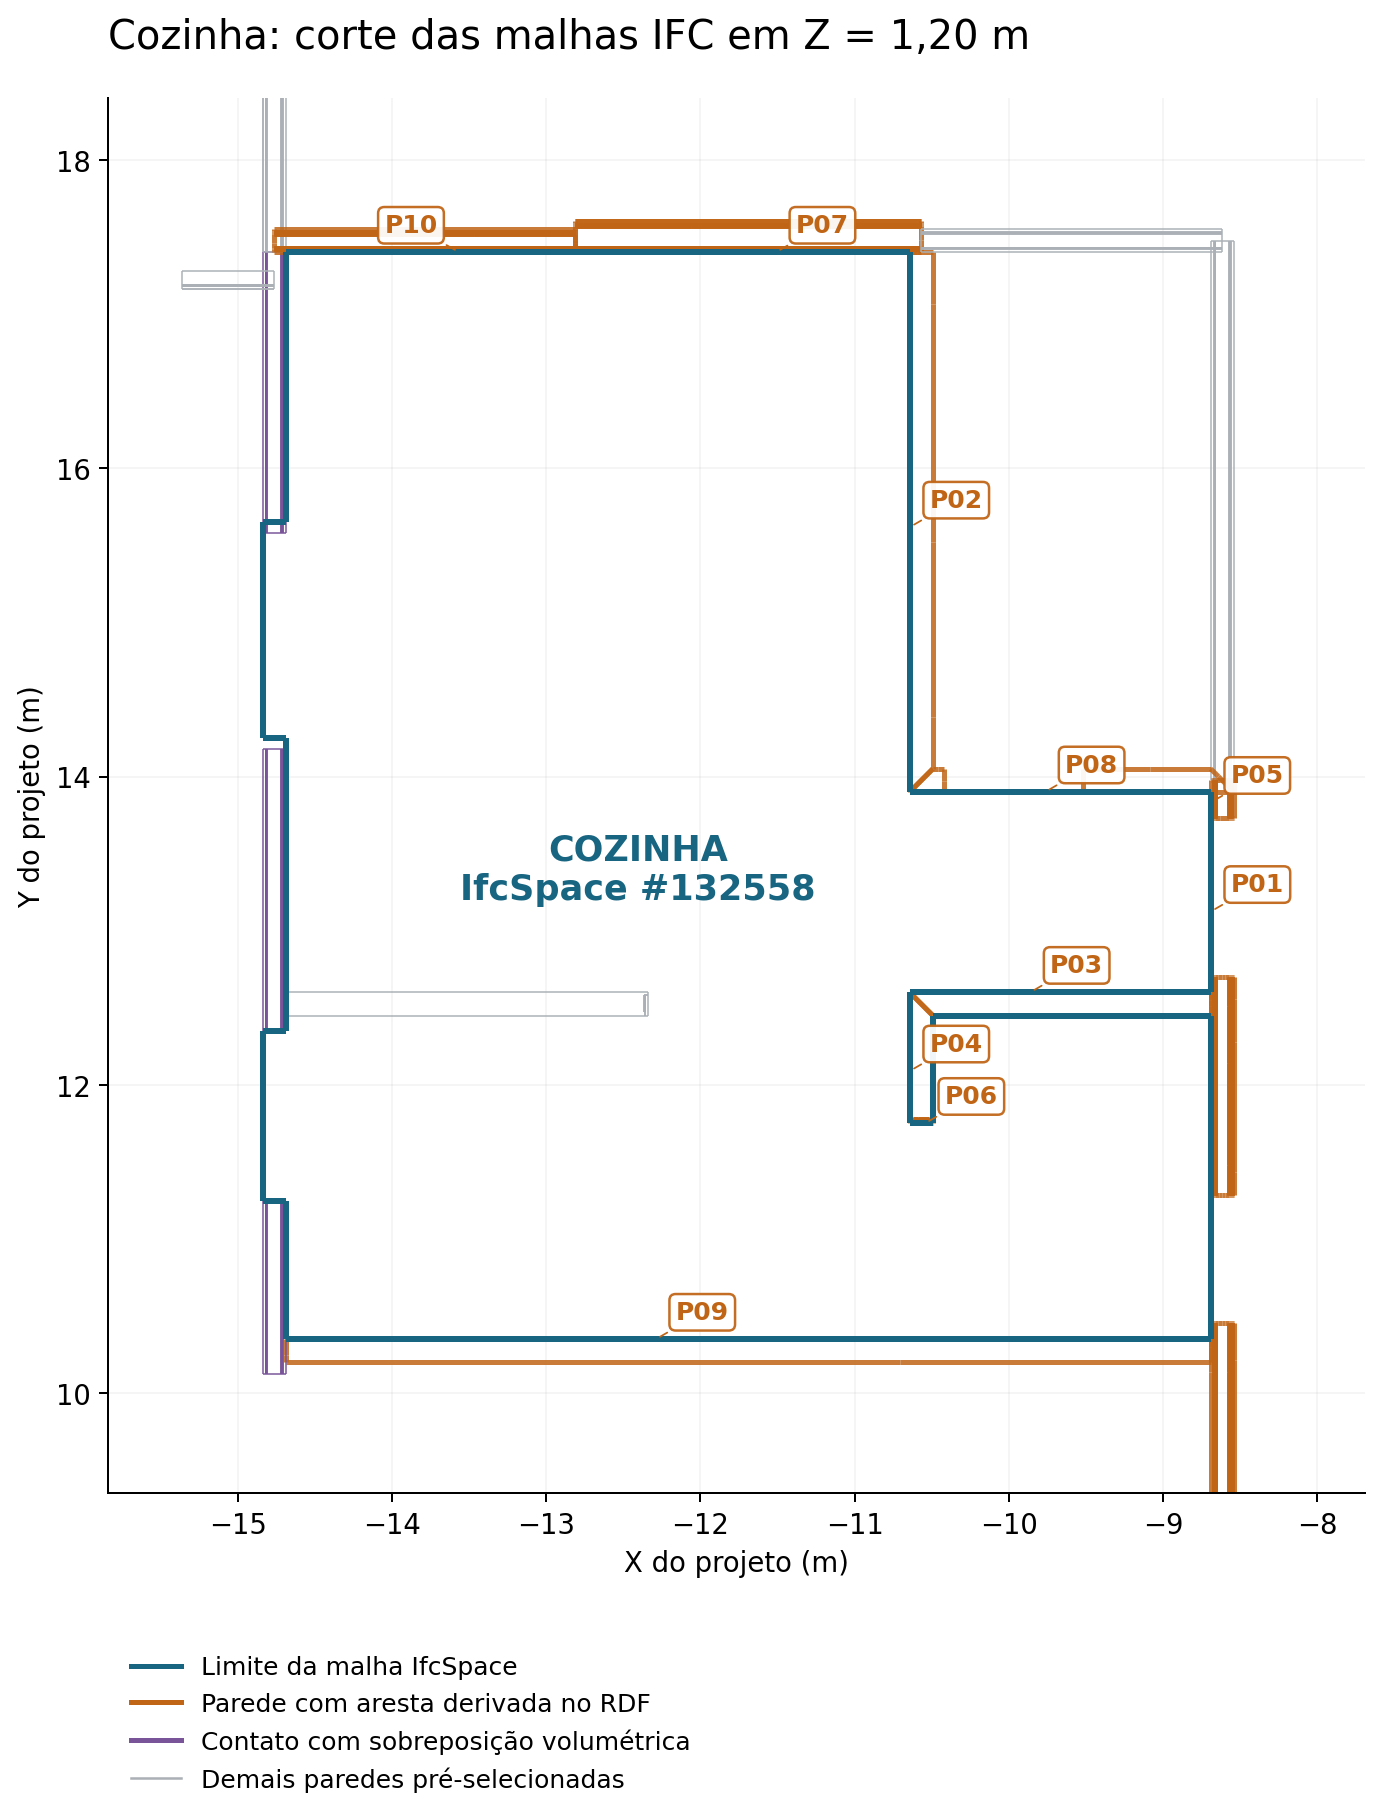

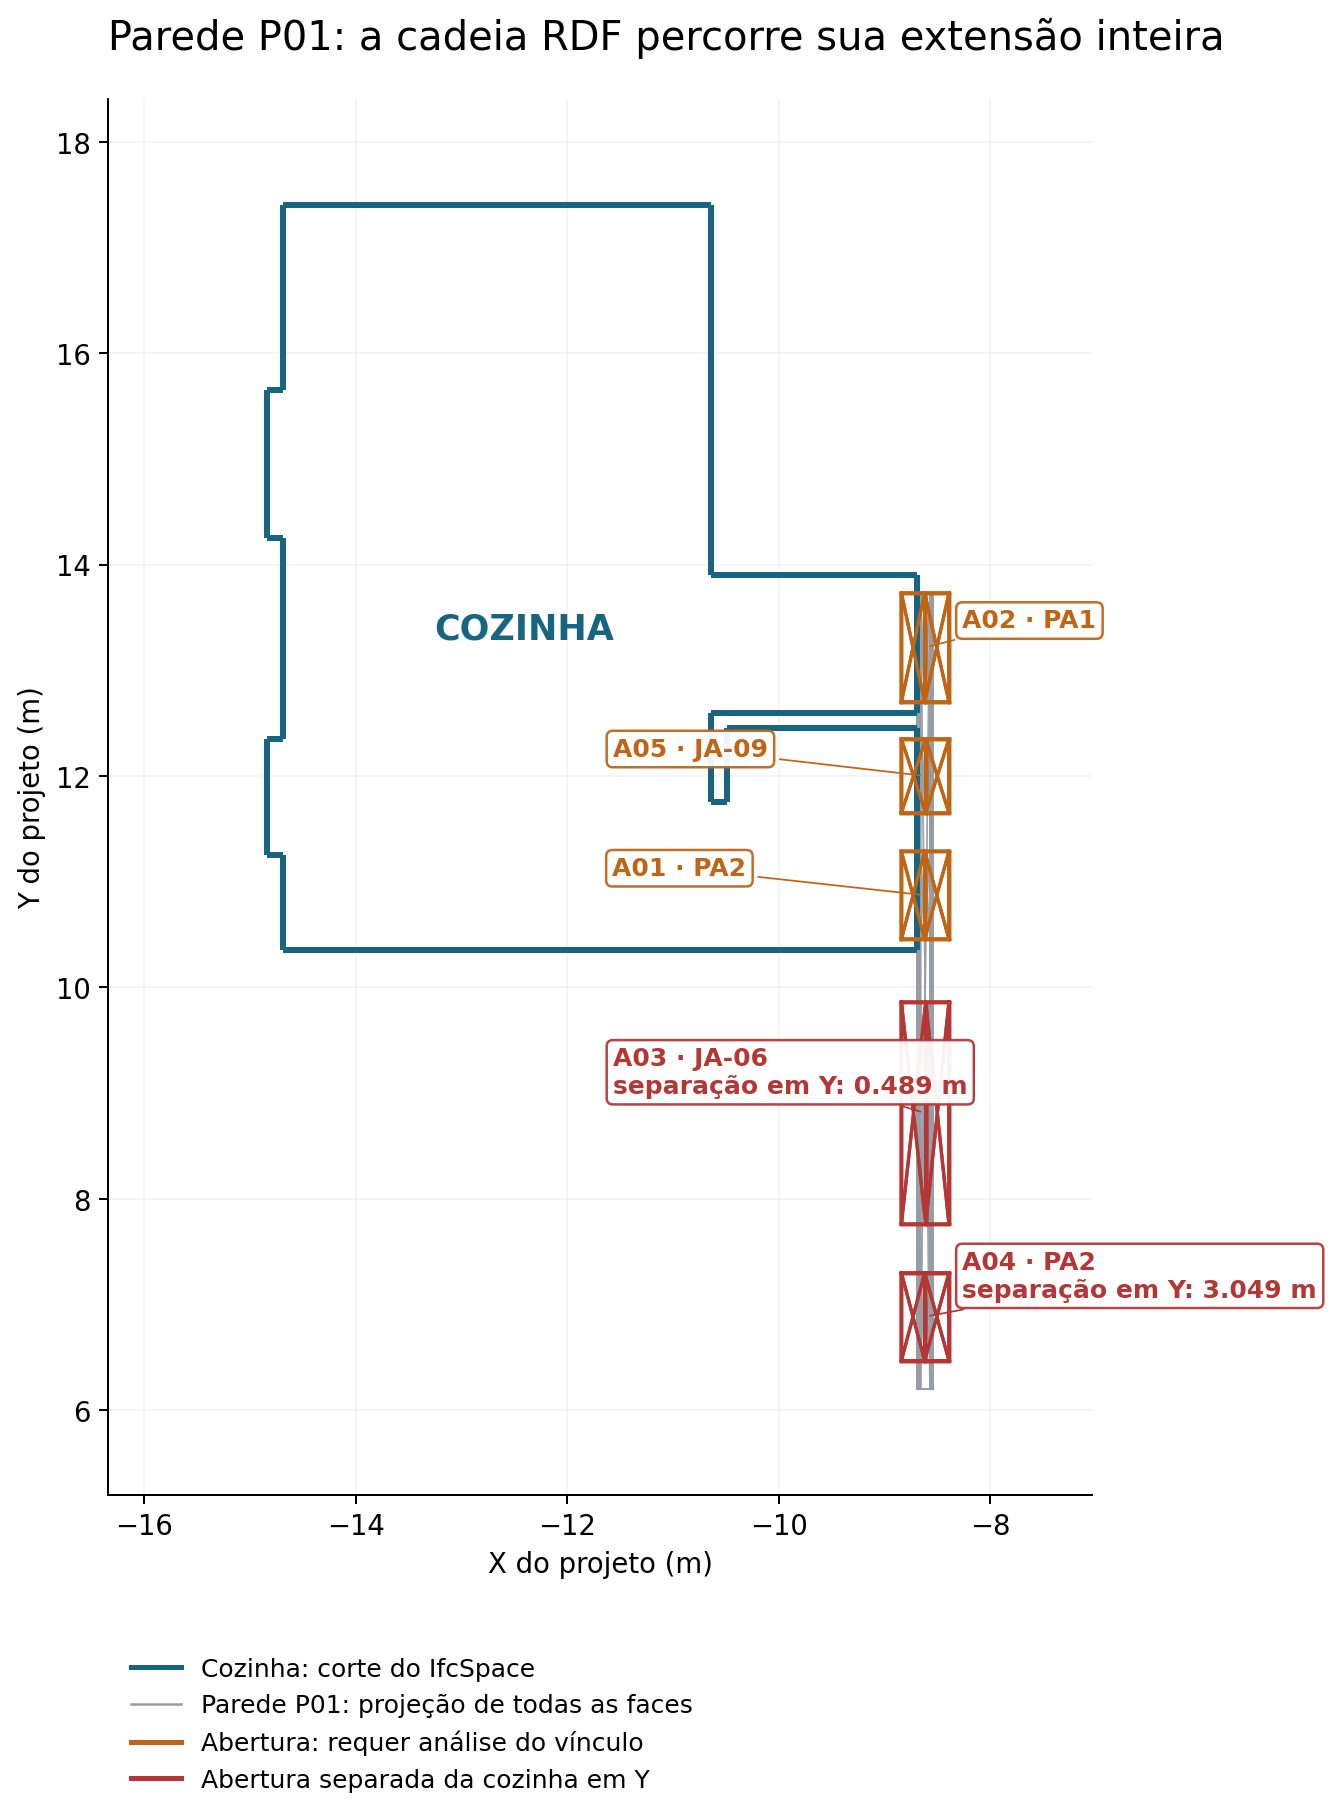

In [4]:
draw(OUT/"conferencia_cozinha_dados.json",CACHE,OUT/"figuras")
from IPython.display import display,Image
for nome in ["01_Cozinha_Corte_IFC.png","02_Parede_Compartilhada_Aberturas.png"]:
    display(Image(filename=str(OUT/"figuras"/nome),width=700))


## 5. Controles e interpretação

A igualdade das tuplas verifica fidelidade da consulta ao IFC para as paredes selecionadas. Não verifica completude da seleção dessas paredes. Os casos separados por caixas fornecem testemunhos geométricos de que a transitividade via parede não demonstra a associação ao cômodo. Nenhum caso com sobreposição de caixas é promovido automaticamente a uma relação arquitetônica.


In [5]:
assert resumo["cadeias_IFC_RDF_identicas"]
assert resumo["extrato_sem_triplas_novas"]
fora=[r for r in cadeias if r["abertura_vs_cozinha"]["teste_3d"]=="fora_do_filtro_espacial_2mm"]
for r in fora:
    assert max(r["abertura_vs_cozinha"]["separacao_caixas_XYZ_m"])>0.002
assert sha(IFC)==EXPECTED_IFC
print("Tuplas IFC–RDF idênticas; extrato sem novas triplas; IFC preservado.")
print("Casos geometricamente separados do ambiente:",len(fora))
print("As conclusões continuam restritas aos dados, à triangulação e aos critérios examinados.")


Tuplas IFC–RDF idênticas; extrato sem novas triplas; IFC preservado.
Casos geometricamente separados do ambiente: 2
As conclusões continuam restritas aos dados, à triangulação e aos critérios examinados.


## 6. Saídas e limites do produto

Salva as tabelas com GUIDs e números STEP, a SPARQL executada, o diagnóstico de todas as aberturas pré-selecionadas, as figuras e um extrato do RDF. O extrato contém somente triplas da saída original; não afirma novas dependências entre portas e ambientes.

O resultado alimenta a matriz de rastreabilidade. A representação da parcela da parede correspondente ao ambiente, a distinção entre tipos de relação espacial e uma referência independente para verificar cobertura continuam como requisitos. Não se resolve a integração entre disciplinas.


In [6]:
manifesto={"procedimento":"Conferência da cozinha IFC–RDF v01","sha256_IFC":sha(IFC),
 "sha256_RDF":resumo["sha256_RDF"],"resumo":resumo,"modulos":HASHES,
 "versoes":{n:version(n) for n in VERSOES},
 "arquivos":{p.relative_to(OUT).as_posix():sha(p) for p in OUT.rglob("*") if p.is_file() and p.name!="manifesto_conferencia_v01.json"}}
(OUT/"manifesto_conferencia_v01.json").write_text(json.dumps(manifesto,ensure_ascii=False,indent=2),encoding="utf8")
pacote=shutil.make_archive(str(ROOT/"CIV2155_Conferencia_Cozinha_v01_Resultados"),"zip",OUT)
print("Resultados:",Path(pacote).name)


Resultados: CIV2155_Conferencia_Cozinha_v01_Resultados.zip
